# Notebook 3 — Trading Rule and Backtest

**Goal of this notebook:**
1. Load the Bonferroni-corrected pair shortlist and price data from Notebook 2's Drive folder
2. For each shortlisted pair, build the trading rule: spread -> rolling z-score -> entry/exit
   rules (exactly as described in the proposal's Phase 2)
3. Backtest the rule on the **Verify period only (2023-2025)** — data the pairs were never
   selected on — trading at the next day's close to avoid look-ahead bias
4. Visualize the spread, the trades, and the resulting equity curve for each pair
5. Save trade-level and daily returns so Notebook 4 can run the t-test / confidence interval

**Important:** this is a simplified, course-project-level backtest (no transaction costs,
slippage, or capital constraints) — good enough to test the statistical question (does the
corrected pair's spread-reversion edge show up out of sample?), not a production trading
system.

In [1]:
# No extra packages needed beyond what Colab already has
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', 200)
plt.rcParams['figure.dpi'] = 110

## 0. Google Drive setup

Same shared Drive folder as before. This notebook reads Notebook 2's output from the
`02_pair_selection` subfolder, and saves its own output to `03_trading_rule_backtest`.

In [2]:
PARENT_FOLDER_ID = '1w9Q2nfcNhew6hzx8eQSCINReUy3OUwE1'
PREV_NOTEBOOK_FOLDER = '02_pair_selection'
THIS_NOTEBOOK_FOLDER = '03_trading_rule_backtest'

from google.colab import auth
auth.authenticate_user()

import google.auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaFileUpload, MediaIoBaseDownload
import io

creds, _ = google.auth.default()
drive_service = build('drive', 'v3', credentials=creds)


def get_or_create_subfolder(parent_id, name):
    query = (f"'{parent_id}' in parents and name='{name}' "
             "and mimeType='application/vnd.google-apps.folder' and trashed=false")
    results = drive_service.files().list(q=query, fields='files(id, name)', supportsAllDrives=True, includeItemsFromAllDrives=True).execute()
    files = results.get('files', [])
    if files:
        return files[0]['id']
    metadata = {'name': name, 'mimeType': 'application/vnd.google-apps.folder', 'parents': [parent_id]}
    folder = drive_service.files().create(body=metadata, fields='id', supportsAllDrives=True).execute()
    print(f"Created new Drive subfolder: {name}")
    return folder['id']


def upload_file(local_path, folder_id):
    filename = local_path.split('/')[-1]
    query = f"'{folder_id}' in parents and name='{filename}' and trashed=false"
    results = drive_service.files().list(q=query, fields='files(id, name)', supportsAllDrives=True, includeItemsFromAllDrives=True).execute()
    existing = results.get('files', [])
    media = MediaFileUpload(local_path, resumable=True)
    if existing:
        drive_service.files().update(fileId=existing[0]['id'], media_body=media, supportsAllDrives=True).execute()
    else:
        metadata = {'name': filename, 'parents': [folder_id]}
        drive_service.files().create(body=metadata, media_body=media, fields='id', supportsAllDrives=True).execute()
    print(f"Uploaded {filename} to Drive.")


def download_file(filename, folder_id, local_path=None):
    local_path = local_path or filename
    query = f"'{folder_id}' in parents and name='{filename}' and trashed=false"
    results = drive_service.files().list(q=query, fields='files(id, name)', supportsAllDrives=True, includeItemsFromAllDrives=True).execute()
    files = results.get('files', [])
    if not files:
        raise FileNotFoundError(f"{filename} not found in Drive folder.")
    request = drive_service.files().get_media(fileId=files[0]['id'], supportsAllDrives=True)
    fh = io.FileIO(local_path, 'wb')
    downloader = MediaIoBaseDownload(fh, request)
    done = False
    while not done:
        _, done = downloader.next_chunk()
    print(f"Downloaded {filename} from Drive.")
    return local_path


prev_folder_id = get_or_create_subfolder(PARENT_FOLDER_ID, PREV_NOTEBOOK_FOLDER)
this_folder_id = get_or_create_subfolder(PARENT_FOLDER_ID, THIS_NOTEBOOK_FOLDER)
print(f"Ready — reading from '{PREV_NOTEBOOK_FOLDER}', saving to '{THIS_NOTEBOOK_FOLDER}'.")

Ready — reading from '02_pair_selection', saving to '03_trading_rule_backtest'.


### Diagnostic: what can this session actually see in `02_pair_selection`?

Run this before the load step below. If the list comes back empty, it almost always means
either (a) this Colab session authenticated with a **different Google account** than the one
that ran Notebook 2 — re-run the auth cell above and pick the account that has access to the
shared folder — or (b) Notebook 2 hasn't actually been run/finished yet.

In [3]:
diag = drive_service.files().list(
    q=f"'{prev_folder_id}' in parents and trashed=false",
    fields='files(id, name, modifiedTime)',
    supportsAllDrives=True,
    includeItemsFromAllDrives=True,
).execute()
found = diag.get('files', [])
print(f"Files visible in '{PREV_NOTEBOOK_FOLDER}' (folder id: {prev_folder_id}):")
if not found:
    print("  (none — see the troubleshooting note above)")
for f in found:
    print(f"  - {f['name']} (modified {f['modifiedTime']})")

Files visible in '02_pair_selection' (folder id: 1F-dG5ttXBmWwjMjzjG7sos-si8P9z0Ea):
  - prices_verify.csv (modified 2026-11-09T07:33:42.145Z)
  - prices_train.csv (modified 2026-11-09T07:33:41.003Z)
  - final_shortlisted_pairs_fdr.csv (modified 2026-11-09T07:33:39.760Z)
  - final_shortlisted_pairs_bonferroni.csv (modified 2026-11-09T07:33:38.519Z)
  - all_pairs_cointegration_results.csv (modified 2026-11-09T07:33:37.422Z)


## 1. Load the shortlist and price data from Notebook 2

In [4]:
for fname in ['final_shortlisted_pairs_bonferroni.csv', 'prices_train.csv', 'prices_verify.csv']:
    download_file(fname, prev_folder_id)

shortlist = pd.read_csv('final_shortlisted_pairs_bonferroni.csv')
prices_train = pd.read_csv('prices_train.csv', index_col=0, parse_dates=True)
prices_verify = pd.read_csv('prices_verify.csv', index_col=0, parse_dates=True)

print(f"Shortlisted pairs (Bonferroni-corrected): {len(shortlist)}")
print(shortlist[['stock_1', 'stock_2', 'p_value']].to_string(index=False))
print()
print(f"Verify period: {prices_verify.index.min().date()} to {prices_verify.index.max().date()} "
      f"({len(prices_verify)} trading days)")

Downloaded final_shortlisted_pairs_bonferroni.csv from Drive.
Downloaded prices_train.csv from Drive.
Downloaded prices_verify.csv from Drive.
Shortlisted pairs (Bonferroni-corrected): 1
stock_1 stock_2  p_value
      V      MA 0.000203

Verify period: 2023-01-03 to 2024-12-31 (502 trading days)


## 2. The trading rule, as a function

For a pair $(A, B)$:
1. Estimate the hedge ratio $\beta$ **from Train data only** (regress $\log P_A$ on $\log
   P_B$) and keep it fixed — we don't re-fit $\beta$ on Verify data, to keep the test honest
2. On Verify data, compute the spread $s_t = \log P_{A,t} - \beta \log P_{B,t}$
3. Compute a rolling z-score using the past 60 days: $z_t = (s_t - \bar{s}_t) / \hat\sigma_t$
4. Entry: if $z_t > 2$, go short the spread (short $A$, long $B$); if $z_t < -2$, go long the
   spread. Exit when $|z_t| < 0.5$. Stop-loss if $|z_t| > 4$ (the relationship may have broken)
5. Trade using the **next day's close** (avoids look-ahead bias — today's signal, tomorrow's
   trade)

In [5]:
def estimate_hedge_ratio(stock_a, stock_b, prices_train):
    """Regress log(A) on log(B) using Train data only; returns beta."""
    log_a = np.log(prices_train[stock_a].values)
    log_b = np.log(prices_train[stock_b].values)
    beta, const = np.polyfit(log_b, log_a, 1)
    return beta


def run_backtest(stock_a, stock_b, beta, prices_verify, window=60,
                  entry_z=2.0, exit_z=0.5, stop_z=4.0):
    """
    Backtests the z-score trading rule for one pair over the Verify period.
    Returns a dict with the daily series (spread, z-score, position, strategy return)
    and a DataFrame of individual trades.
    """
    log_a = np.log(prices_verify[stock_a])
    log_b = np.log(prices_verify[stock_b])
    spread = log_a - beta * log_b

    roll_mean = spread.rolling(window, min_periods=window).mean()
    roll_std = spread.rolling(window, min_periods=window).std()
    z = (spread - roll_mean) / roll_std

    position = np.zeros(len(z))   # +1 = long spread, -1 = short spread, 0 = flat
    current = 0

    for i in range(len(z)):
        zt = z.iloc[i]
        if np.isnan(zt):
            position[i] = 0
            continue
        if current == 0:
            if zt > entry_z:
                current = -1
            elif zt < -entry_z:
                current = 1
        else:
            if abs(zt) < exit_z or abs(zt) > stop_z:
                current = 0
        position[i] = current

    # Lag the position by 1 day: today's signal trades at TOMORROW's close (no look-ahead)
    position_lagged = pd.Series(position, index=z.index).shift(1).fillna(0)

    # Daily P&L approximation: position * day-over-day change in the (log) spread
    spread_change = spread.diff()
    daily_return = position_lagged * spread_change
    daily_return = daily_return.fillna(0)

    # Extract individual trades: contiguous runs where position_lagged != 0
    trades = []
    in_trade = False
    trade_start = None
    trade_dir = 0
    for i, (date, pos) in enumerate(position_lagged.items()):
        if pos != 0 and not in_trade:
            in_trade = True
            trade_start = date
            trade_dir = pos
        elif pos == 0 and in_trade:
            in_trade = False
            trade_end = date
            trade_return = daily_return.loc[trade_start:trade_end].sum()
            trades.append({
                'pair': f"{stock_a}-{stock_b}",
                'direction': 'long_spread' if trade_dir == 1 else 'short_spread',
                'entry_date': trade_start,
                'exit_date': trade_end,
                'log_return': trade_return,
                'pct_return': np.exp(trade_return) - 1,
            })
    if in_trade:  # close out any trade still open at the end of the period
        trade_end = position_lagged.index[-1]
        trade_return = daily_return.loc[trade_start:trade_end].sum()
        trades.append({
            'pair': f"{stock_a}-{stock_b}",
            'direction': 'long_spread' if trade_dir == 1 else 'short_spread',
            'entry_date': trade_start,
            'exit_date': trade_end,
            'log_return': trade_return,
            'pct_return': np.exp(trade_return) - 1,
        })

    trades_df = pd.DataFrame(trades)

    return {
        'pair': f"{stock_a}-{stock_b}",
        'spread': spread,
        'z': z,
        'position': position_lagged,
        'daily_return': daily_return,
        'trades': trades_df,
    }

## 3. Run the backtest for every shortlisted pair

In [6]:
backtest_results = {}

for _, row in shortlist.iterrows():
    stock_a, stock_b = row['stock_1'], row['stock_2']
    beta = estimate_hedge_ratio(stock_a, stock_b, prices_train)
    result = run_backtest(stock_a, stock_b, beta, prices_verify)
    result['beta'] = beta
    backtest_results[f"{stock_a}-{stock_b}"] = result
    n_trades = len(result['trades'])
    print(f"{stock_a}-{stock_b}: beta={beta:.4f}, {n_trades} trades in the Verify period")

V-MA: beta=0.7894, 10 trades in the Verify period


## 4. Visualize each pair: price, spread/z-score with trades, and equity curve

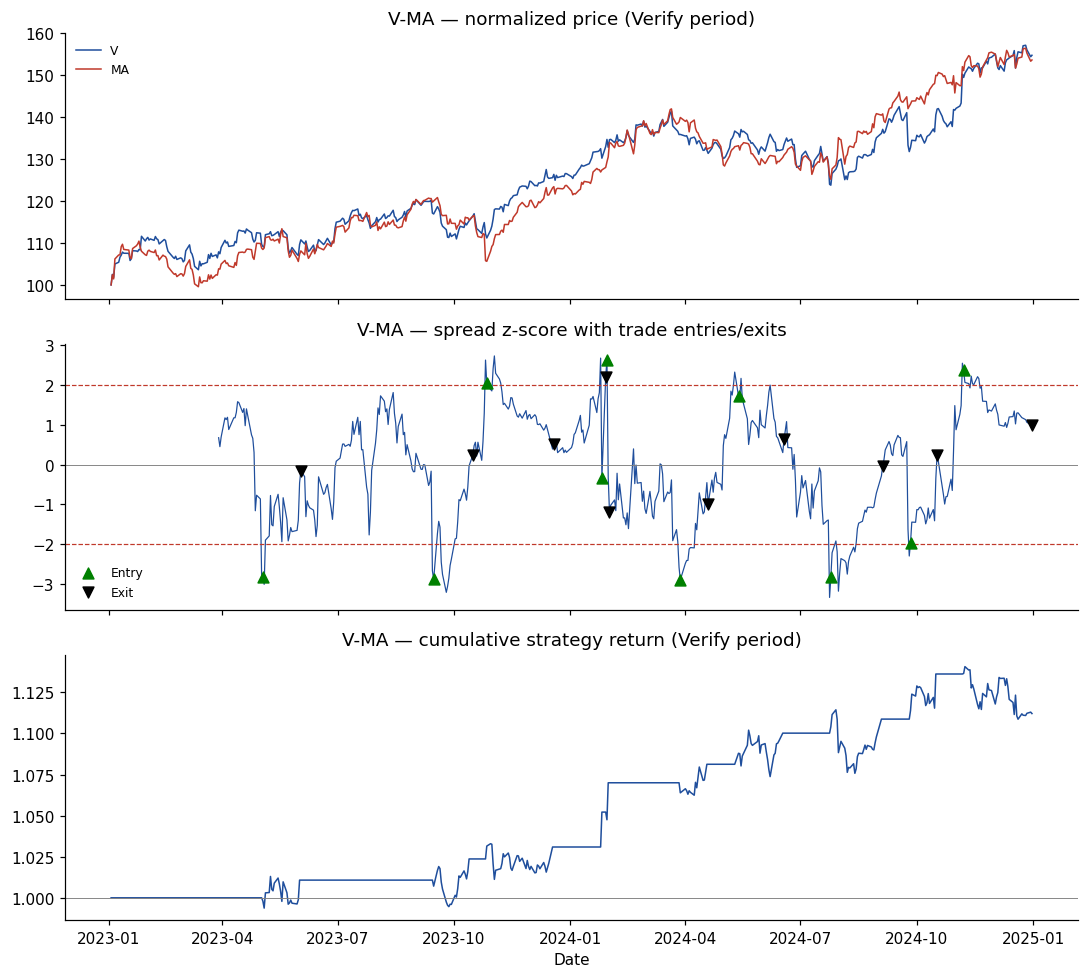

In [7]:
for pair_name, result in backtest_results.items():
    stock_a, stock_b = pair_name.split('-')
    z = result['z']
    position = result['position']
    daily_return = result['daily_return']
    trades = result['trades']

    fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

    # (a) Normalized prices, Verify period
    norm_a = 100 * prices_verify[stock_a] / prices_verify[stock_a].iloc[0]
    norm_b = 100 * prices_verify[stock_b] / prices_verify[stock_b].iloc[0]
    axes[0].plot(norm_a.index, norm_a.values, label=stock_a, color='#1f4e9c', linewidth=1)
    axes[0].plot(norm_b.index, norm_b.values, label=stock_b, color='#c0392b', linewidth=1)
    axes[0].set_title(f'{pair_name} — normalized price (Verify period)')
    axes[0].legend(fontsize=8, frameon=False)
    axes[0].spines[['top', 'right']].set_visible(False)

    # (b) Z-score with entry/exit thresholds and actual trade entry/exit points marked
    axes[1].plot(z.index, z.values, color='#1f4e9c', linewidth=0.8)
    axes[1].axhline(2, color='#c0392b', linestyle='--', linewidth=0.8)
    axes[1].axhline(-2, color='#c0392b', linestyle='--', linewidth=0.8)
    axes[1].axhline(0, color='gray', linewidth=0.6)
    if len(trades) > 0:
        axes[1].scatter(trades['entry_date'], z.reindex(trades['entry_date']),
                         color='green', marker='^', s=50, label='Entry', zorder=5)
        axes[1].scatter(trades['exit_date'], z.reindex(trades['exit_date']),
                         color='black', marker='v', s=50, label='Exit', zorder=5)
    axes[1].set_title(f'{pair_name} — spread z-score with trade entries/exits')
    axes[1].legend(fontsize=8, frameon=False)
    axes[1].spines[['top', 'right']].set_visible(False)

    # (c) Equity curve (cumulative strategy return)
    equity = np.exp(daily_return.cumsum())
    axes[2].plot(equity.index, equity.values, color='#1f4e9c', linewidth=1)
    axes[2].axhline(1.0, color='gray', linewidth=0.6)
    axes[2].set_title(f'{pair_name} — cumulative strategy return (Verify period)')
    axes[2].set_xlabel('Date')
    axes[2].spines[['top', 'right']].set_visible(False)

    fig.tight_layout()
    plt.show()

## 5. Trade return distributions

A quick look at the spread of individual trade outcomes per pair, before formal testing in
Notebook 4.

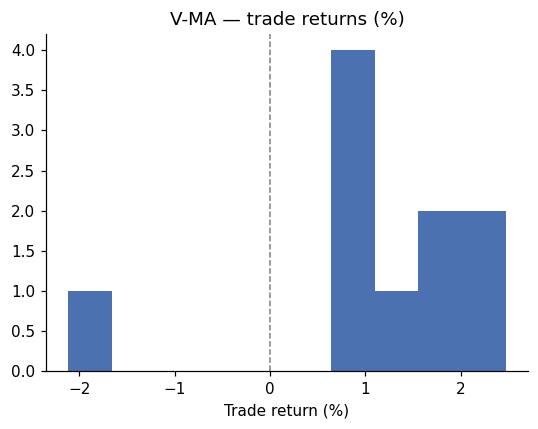

In [8]:
n_pairs = len(backtest_results)
fig, axes = plt.subplots(1, n_pairs, figsize=(5 * n_pairs, 4), squeeze=False)
axes = axes[0]

for ax, (pair_name, result) in zip(axes, backtest_results.items()):
    trades = result['trades']
    if len(trades) == 0:
        ax.set_title(f'{pair_name} — no trades')
        continue
    ax.hist(trades['pct_return'] * 100, bins=min(15, max(5, len(trades))), color='#1f4e9c', alpha=0.8)
    ax.axvline(0, color='gray', linestyle='--', linewidth=1)
    ax.set_title(f'{pair_name} — trade returns (%)')
    ax.set_xlabel('Trade return (%)')
    ax.spines[['top', 'right']].set_visible(False)

fig.tight_layout()
plt.show()

## 6. Summary table across pairs

In [9]:
summary_rows = []
for pair_name, result in backtest_results.items():
    trades = result['trades']
    daily_return = result['daily_return']
    total_return = np.exp(daily_return.sum()) - 1
    win_rate = (trades['pct_return'] > 0).mean() if len(trades) > 0 else np.nan
    avg_trade_return = trades['pct_return'].mean() if len(trades) > 0 else np.nan
    summary_rows.append({
        'pair': pair_name,
        'beta': round(result['beta'], 4),
        'n_trades': len(trades),
        'total_return_%': round(total_return * 100, 2),
        'win_rate': round(win_rate, 3) if not np.isnan(win_rate) else None,
        'avg_trade_return_%': round(avg_trade_return * 100, 3) if not np.isnan(avg_trade_return) else None,
    })

summary_df = pd.DataFrame(summary_rows)
summary_df

,pair,beta,n_trades,total_return_%,win_rate,avg_trade_return_%
0,V-MA,0.7894,10,11.21,0.9,1.075


## 7. Save everything for Notebook 4

In [10]:
# Combine all trades across pairs into one file
all_trades = pd.concat([result['trades'] for result in backtest_results.values()], ignore_index=True)
all_trades.to_csv('all_trades.csv', index=False)

# Daily strategy returns per pair, as one wide CSV (date x pair)
daily_returns_wide = pd.DataFrame({
    pair_name: result['daily_return'] for pair_name, result in backtest_results.items()
})
daily_returns_wide.to_csv('daily_strategy_returns.csv')

summary_df.to_csv('backtest_summary.csv', index=False)

output_files = ['all_trades.csv', 'daily_strategy_returns.csv', 'backtest_summary.csv']
for fname in output_files:
    upload_file(fname, this_folder_id)

print(f"Saved locally and uploaded to Drive ({THIS_NOTEBOOK_FOLDER}): {', '.join(output_files)}")

Uploaded all_trades.csv to Drive.
Uploaded daily_strategy_returns.csv to Drive.
Uploaded backtest_summary.csv to Drive.
Saved locally and uploaded to Drive (03_trading_rule_backtest): all_trades.csv, daily_strategy_returns.csv, backtest_summary.csv


## Next notebook

**Notebook 4** takes `all_trades.csv` and `daily_strategy_returns.csv` from this notebook's
Drive folder and runs the formal hypothesis test (t-test, 95% confidence interval, and
Newey-West-adjusted standard errors to account for the independence issue) to check whether
the average return is really different from zero.